In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Social_Network_Ads.csv to Social_Network_Ads.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn. metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import spacy
nlp=spacy.load("en_core_web_sm")
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree



In [ ]:
df=pd.read_csv('Social_Network_Ads.csv', encoding='latin1')
print(df)


      User ID  Gender  Age  EstimatedSalary  Purchased
0    15624510    Male   19            19000          0
1    15810944    Male   35            20000          0
2    15668575  Female   26            43000          0
3    15603246  Female   27            57000          0
4    15804002    Male   19            76000          0
..        ...     ...  ...              ...        ...
395  15691863  Female   46            41000          1
396  15706071    Male   51            23000          1
397  15654296  Female   50            20000          1
398  15755018    Male   36            33000          0
399  15594041  Female   49            36000          1

[400 rows x 5 columns]


In [ ]:
print(df.shape)
print(df.info())

(400, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None


In [ ]:
print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())

print(df.describe())

print(df["Purchased"].value_counts())

print(df.corr(numeric_only=True))

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Duplicates: 0
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000
Purchased
0    257
1    143
Name: count, dtype: int64
                  User ID       Age  EstimatedSalary  Purchased
User ID          1.000000 -0.000721         0.071097   0.007120
Age             -0.000721  1.000000         0.155238   0.622454
EstimatedSalary  0.071097  0.155238         1.000000   0.362083
Purchased

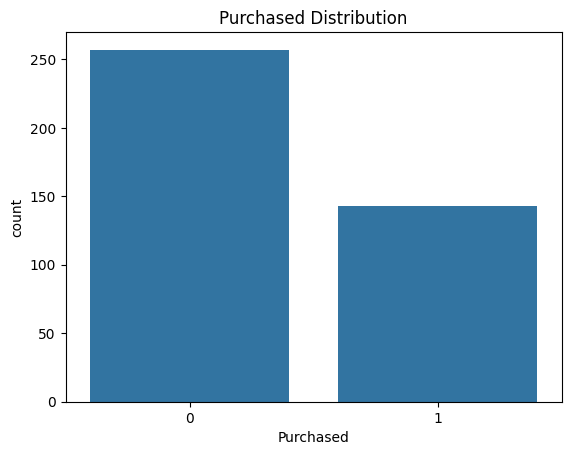

In [ ]:

sns.countplot(x="Purchased", data=df)
plt.title("Purchased Distribution")
plt.show()

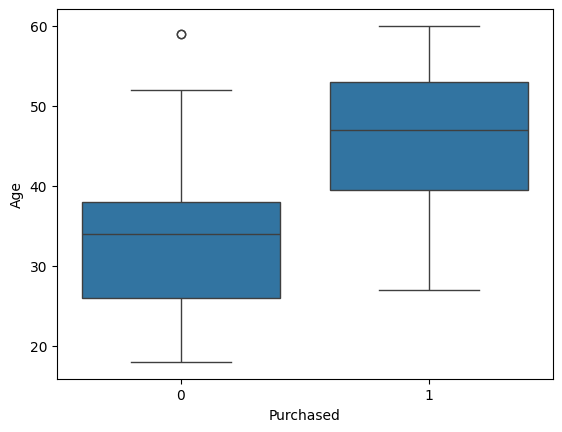

In [ ]:

sns.boxplot(x="Purchased", y="Age", data=df)
plt.show()

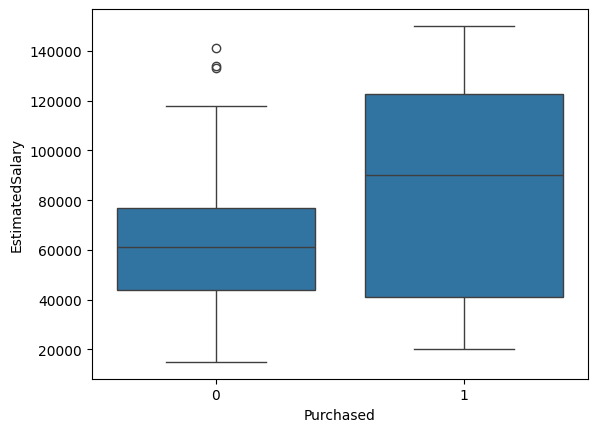

In [ ]:

sns.boxplot(x="Purchased", y="EstimatedSalary", data=df)
plt.show()

In [ ]:

df = df.drop("User ID", axis=1)

df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})

print(df)

     Gender  Age  EstimatedSalary  Purchased
0         0   19            19000          0
1         0   35            20000          0
2         1   26            43000          0
3         1   27            57000          0
4         0   19            76000          0
..      ...  ...              ...        ...
395       1   46            41000          1
396       0   51            23000          1
397       1   50            20000          1
398       0   36            33000          0
399       1   49            36000          1

[400 rows x 4 columns]


In [ ]:
X = df.drop("Purchased", axis=1)
y = df["Purchased"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (320, 3)
Testing data: (80, 3)


In [ ]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42
)

In [ ]:
# 7. TRAIN MODEL
model.fit(X_train, y_train)

# 8. PREDICTIONS
y_pred = model.predict(X_test)

# 9. EVALUATION
accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Random Forest Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92        51
           1       0.84      0.90      0.87        29

    accuracy                           0.90        80
   macro avg       0.89      0.90      0.89        80
weighted avg       0.90      0.90      0.90        80



[[46  5]
 [ 3 26]]


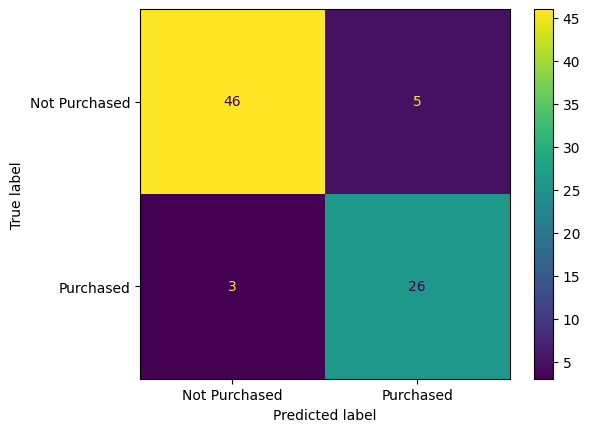

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Purchased", "Purchased"]
)

disp.plot()
plt.show()

In [ ]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.90      0.92        51
           1       0.84      0.90      0.87        29

    accuracy                           0.90        80
   macro avg       0.89      0.90      0.89        80
weighted avg       0.90      0.90      0.90        80



In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

print(importance.sort_values(by="Importance", ascending=False))

           Feature  Importance
2  EstimatedSalary    0.497376
1              Age    0.494456
0           Gender    0.008168


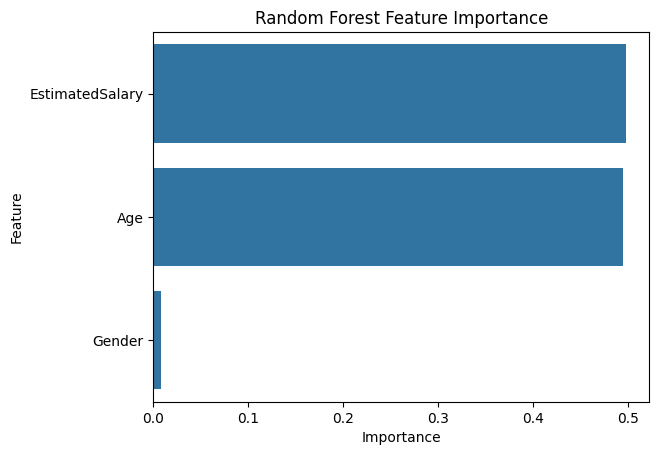

In [ ]:
sns.barplot(
    x="Importance",
    y="Feature",
    data=importance.sort_values(by="Importance", ascending=False)
)

plt.title("Random Forest Feature Importance")
plt.show()

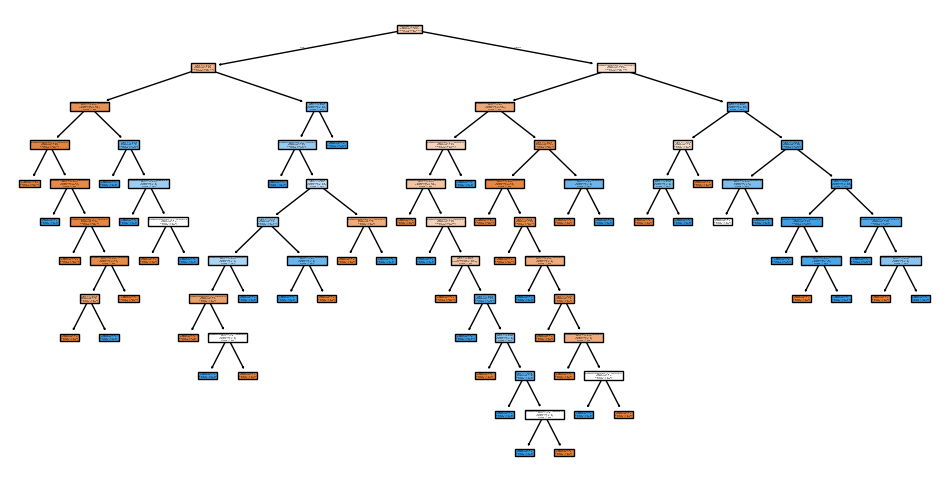

In [ ]:
plt.figure(figsize=(12,6))
plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)
plt.show()